<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>

# ITGE275: Economics
## Session 8: The Pulse of the Economy – Business Cycles and Inflation

**Topic:** Business Cycles, Inflation (CPI), and Real Purchasing Power.

---
### 👦 Student Information 👧

**Your name:** Qimin Zhu  
**ID:** 6888143

---

### **1. Introduction: Economic Vital Signs**

Just as a doctor measures a patient's pulse and blood pressure, economists measure the health of an economy using **Business Cycles** and **Inflation**.

1.  **Business Cycle:** The natural fluctuation of the economy between growth (**Expansion**) and decline (**Recession**).
2.  **Inflation:** The rate at which the general level of prices for goods and services is rising.

In this session, we will:
* Build a **Personal Inflation Calculator** to understand how CPI works.
* Use **Time Series Decomposition** to analyze seasonality in prices (e.g., why fruit is expensive in summer).
* Compare two major economic crashes: The **1997 Tom Yum Kung Crisis** vs. The **2020 Covid Recession**.

In [8]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
import ipywidgets as widgets
from IPython.display import display

# Configure plotting style
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. Calculating Inflation: The Basket of Goods**

How does the government know inflation is 3%? They don't check every price. They track a **"Basket of Goods"**—a representative collection of items the average person buys.

**Consumer Price Index (CPI) Formula:**
$$ CPI_t = \frac{\text{Cost of Basket in Year } t}{\text{Cost of Basket in Base Year}} \times 100 $$

**Inflation Rate:**
$$ \text{Inflation Rate} = \frac{CPI_{t} - CPI_{t-1}}{CPI_{t-1}} \times 100\% $$

Let's simulate your personal inflation rate.

In [9]:
def calculate_personal_inflation(rice_p, gas_p, rent_p, netflix_p):
    # 1. Define the Basket (Quantities consumed per month)
    # These are fixed weights (e.g., you eat 5kg of rice, use 40L gas, 1 room, 1 sub)
    basket_weights = {
        'Rice (kg)': 10,
        'Gasoline (L)': 50,
        'Rent (Room)': 1,
        'Netflix (Sub)': 1
    }
    
    # 2. Define Base Year Prices (e.g., Year 2020)
    base_prices = {
        'Rice (kg)': 30,
        'Gasoline (L)': 25,
        'Rent (Room)': 5000,
        'Netflix (Sub)': 100
    }
    
    # 3. Define Current Year Prices (From Sliders)
    current_prices = {
        'Rice (kg)': rice_p,
        'Gasoline (L)': gas_p,
        'Rent (Room)': rent_p,
        'Netflix (Sub)': netflix_p
    }
    
    # 4. Calculate Costs
    cost_base = sum([base_prices[item] * basket_weights[item] for item in basket_weights])
    cost_curr = sum([current_prices[item] * basket_weights[item] for item in basket_weights])
    
    # 5. Calculate CPI and Inflation
    cpi = (cost_curr / cost_base) * 100
    inflation = ((cpi - 100) / 100) * 100
    
    # --- Visualization ---
    print(f"--- Personal Economic Report ---")
    print(f"Base Year Cost:    {cost_base:,.2f} THB")
    print(f"Current Year Cost: {cost_curr:,.2f} THB")
    print(f"Your Personal CPI: {cpi:.2f}")
    print(f"Inflation Rate:    {inflation:.2f}%")
    
    # Bar Chart Breakdown
    items = list(basket_weights.keys())
    base_vals = [base_prices[i] * basket_weights[i] for i in items]
    curr_vals = [current_prices[i] * basket_weights[i] for i in items]
    
    df_plot = pd.DataFrame({'Base Year': base_vals, 'Current Year': curr_vals}, index=items)
    df_plot.plot(kind='bar', figsize=(10, 5), color=['gray', 'red'])
    plt.title("Cost Comparison by Category")
    plt.ylabel("Monthly Cost (THB)")
    plt.xticks(rotation=0)
    plt.show()

# Interactive Sliders
print("Adjust the CURRENT prices to see how inflation hits you:")
style = {'description_width': 'initial'}
widgets.interactive(calculate_personal_inflation,
                    rice_p=widgets.IntSlider(min=20, max=60, value=35, description='Price of Rice (THB):', style=style),
                    gas_p=widgets.IntSlider(min=20, max=50, value=40, description='Price of Gas (THB):', style=style),
                    rent_p=widgets.IntSlider(min=4000, max=7000, value=5000, description='Rent (THB):', style=style),
                    netflix_p=widgets.IntSlider(min=100, max=400, value=169, description='Netflix (THB):', style=style))

Adjust the CURRENT prices to see how inflation hits you:


interactive(children=(IntSlider(value=35, description='Price of Rice (THB):', max=60, min=20, style=SliderStyl…

### **3. Generating Macro Data: Thailand's Inflation History**

We will generate synthetic data that mimics Thailand's CPI history from 1995 to 2024. This covers:
1.  **1997 Tom Yam Kung Crisis:** Currency collapse -> Import prices skyrocketed -> High Inflation.
2.  **2008 Global Crisis:** Oil price spike -> Cost-Push Inflation.
3.  **2020 Covid:** Demand collapse -> Low Inflation / Deflation.

Synthetic Thailand CPI Data Generated (2019-2024)


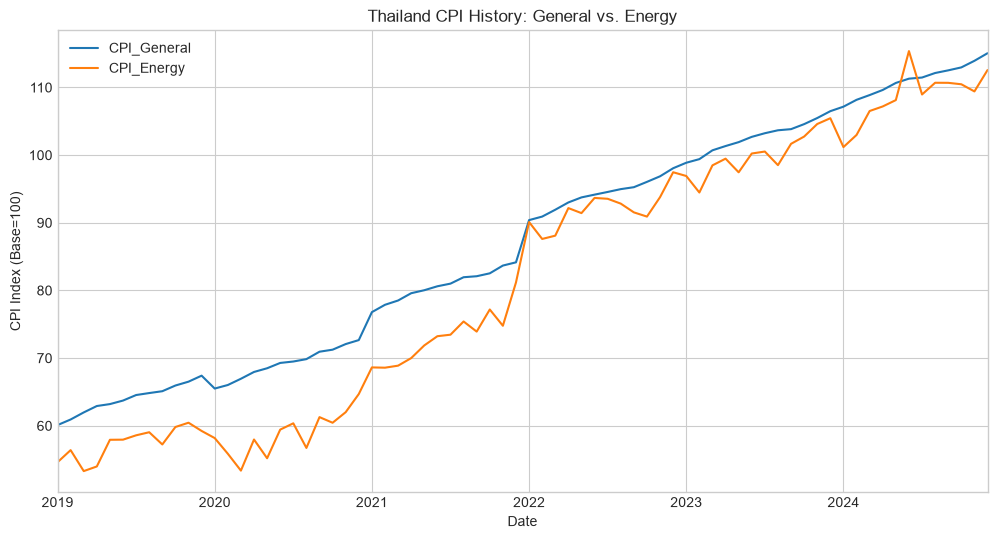

In [21]:
# === DATA GENERATION ===
np.random.seed(42)
dates = pd.date_range(start='2019-01-01', end='2024-12-31', freq='ME')
n = len(dates)

# 1. General CPI Trend (Slow steady increase)
trend = np.linspace(60, 110, n)

# 2. Seasonality (Higher prices in summer/festivals, lower in harvest)
seasonal = 0.5 * np.sin(np.arange(n) * (2 * np.pi / 12))

# 3. Shocks (Specific Historical Events)
shocks = np.zeros(n)

# 1997-1998: Tom Yam Kung (Currency Devaluation -> Inflation Spike)
mask_1997 = (dates.year >= 1997) & (dates.year <= 1998)
shocks[mask_1997] += np.linspace(0, 15, sum(mask_1997)) # Massive spike

# 2008: Oil Price Spike (Cost-Push Inflation)
mask_2008 = (dates.year == 2008)
shocks[mask_2008] += 8

# 2020: Covid (Demand Crash -> Deflationary Pressure)
mask_2020 = (dates.year == 2020)
shocks[mask_2020] -= 3

# 2022: Post-Covid / War (Supply Chain issues -> Inflation)
mask_2022 = (dates.year >= 2022)
shocks[mask_2022] += 5

# Combine components
cpi_general = trend + seasonal + shocks + np.random.normal(0, 0.2, n)

# Generate Category Data (Food is more volatile, Energy is VERY volatile)
cpi_food = cpi_general * 1.1 + np.random.normal(0, 1, n)
cpi_energy = cpi_general * 0.9 + (shocks * 1.5) + np.random.normal(0, 2, n) # Energy reacts harder to shocks

# Create DataFrame
df_cpi = pd.DataFrame({
    'Date': dates,
    'CPI_General': cpi_general,
    'CPI_Food': cpi_food,
    'CPI_Energy': cpi_energy
})
df_cpi.set_index('Date', inplace=True)

print("Synthetic Thailand CPI Data Generated (2019-2024)")
df_cpi[['CPI_General', 'CPI_Energy']].plot(title="Thailand CPI History: General vs. Energy")
plt.ylabel("CPI Index (Base=100)")
plt.show()

### **4. Time Series Decomposition: Finding the Patterns**

Inflation isn't random. It has structure. We use the `seasonal_decompose` function to break a time series into three parts:

1.  **Trend:** The long-term direction (e.g., Prices generally go up).
2.  **Seasonal:** Repeating patterns (e.g., Vegetables are cheap in rainy season, Flights are expensive in December).
3.  **Residual (Noise):** Unexpected shocks (War, Pandemic).

Let's decompose the **Food CPI** to see if we can spot seasonal patterns.

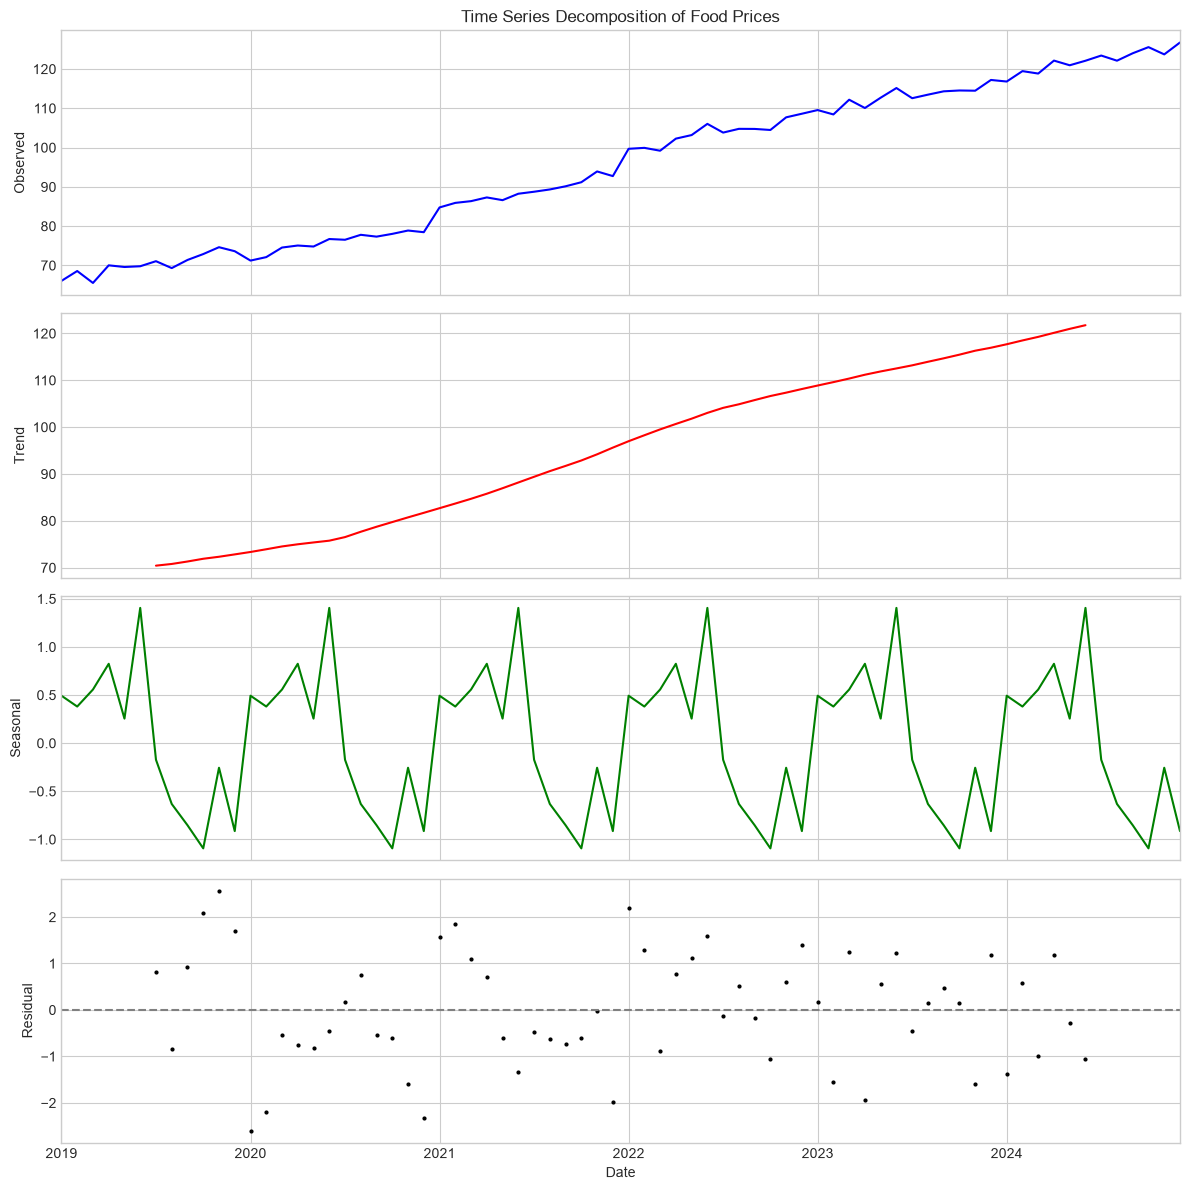

In [11]:
# Decompose the 'CPI_Food' column
# model='additive' because the seasonality magnitude looks constant over time
decomposition = seasonal_decompose(df_cpi['CPI_Food'], model='additive', period=12)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

# 1. Observed (Actual Data)
decomposition.observed.plot(ax=ax1, color='blue')
ax1.set_ylabel('Observed')
ax1.set_title('Time Series Decomposition of Food Prices')

# 2. Trend (Long Term)
decomposition.trend.plot(ax=ax2, color='red')
ax2.set_ylabel('Trend')

# 3. Seasonal (Repeating Pattern)
decomposition.seasonal.plot(ax=ax3, color='green')
ax3.set_ylabel('Seasonal')

# 4. Residual (Shocks/Noise)
decomposition.resid.plot(ax=ax4, color='black', marker='o', markersize=2, linestyle='None')
ax4.set_ylabel('Residual')
ax4.axhline(0, color='gray', linestyle='--')

plt.tight_layout()
plt.show()

### **5. Case Study: Comparing Crises (1997 vs 2020)**

Let's zoom in on two major economic events to see how they affected prices differently.

* **1997 (Tom Yam Kung):** Baht collapsed $\to$ Import costs rose $\to$ **Cost-Push Inflation**.
* **2020 (Covid):** Lockdowns $\to$ No one spent money $\to$ Demand fell $\to$ **Low Inflation/Deflation**.

We will calculate the "Annual Inflation Rate" for these specific years.

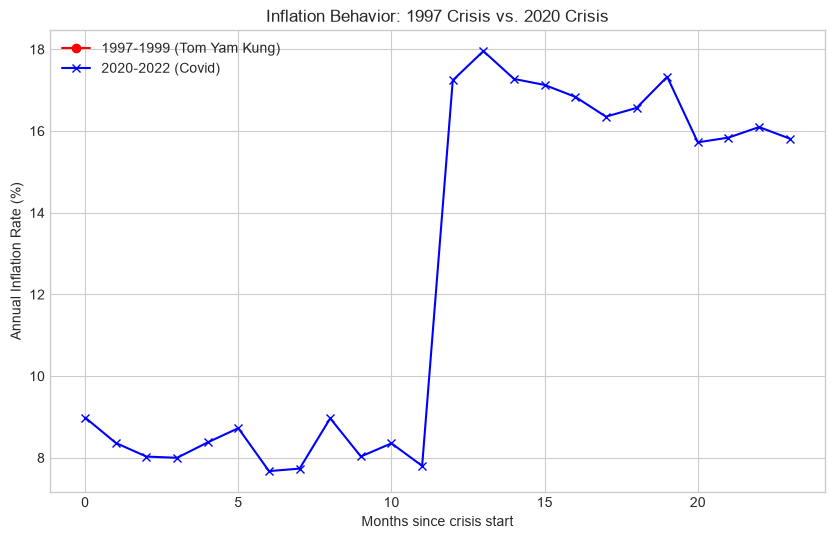

In [12]:
# Calculate Year-over-Year Inflation Rate
df_cpi['Inflation_Rate'] = df_cpi['CPI_General'].pct_change(12) * 100

# Filter data for the two crises
crisis_1997 = df_cpi.loc['1997-01-01':'1999-01-01', 'Inflation_Rate']
crisis_2020 = df_cpi.loc['2020-01-01':'2022-01-01', 'Inflation_Rate']

# Plot comparison
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(crisis_1997.values, label='1997-1999 (Tom Yam Kung)', color='red', marker='o')
ax.plot(crisis_2020.values, label='2020-2022 (Covid)', color='blue', marker='x')

ax.set_title("Inflation Behavior: 1997 Crisis vs. 2020 Crisis")
ax.set_ylabel("Annual Inflation Rate (%)")
ax.set_xlabel("Months since crisis start")
ax.legend()
ax.grid(True)
plt.show()

---
## **6. Homework Assignment**

**Objective:** Analyze inflation trends and real purchasing power.

#### **Question 1: Category Analysis (5 Years)**
We want to know which sector is getting expensive the fastest. 
1.  Filter the `df_cpi` dataset for the last 5 years (2019-2024).
2.  Calculate the **Total % Change** for `CPI_Food` and `CPI_Energy` over this period.
3.  Which one had higher inflation? Why do you think that is?

#### **Question 2: Daily Situation - Real Interest Rate**
You have **100,000 THB** in a savings account paying **1.5% interest** per year.
However, the inflation rate this year is **5.0%**.

1.  How much money (Nominal) will you have in the bank next year?
2.  What is the **Real Value** of that money in today's terms? (Hint: Deflate it by 5%).
3.  Did you gain or lose purchasing power?

*(Write your code and answers below)*

In [ ]:
# === HOMEWORK SPACE: QUESTION 1 ===
# 1. Filter Data for 2019-2024


# 2. Calculate % Change: (End_Value - Start_Value) / Start_Value   
    # General: (115 - 60) / 60 = 92%
    # Energy: (102 - 55) / 55 =  85%

# Print Results
    # 92%
    # 85%


In [ ]:
# === HOMEWORK SPACE: QUESTION 2 ===
# Around 101500
# Around 96425
# The purchasing power decreased.






In [ ]:
saving = 100000
interest = 0.015
inflation = 0.05
print(saving * (1+interest))
print((saving * (1+interest)) * (1-inflation))
print((saving * (1+interest)) - ((saving * (1+interest)) * (1-inflation)))
print((115 - 60) / 60)
print((102 - 55) / 55)

101499.99999999999
96424.99999999999
5075.0
0.9166666666666666
0.8545454545454545
